# Modularity on the Karate Club Graph
**DSC212: Graph Theory : Research Assignment**

Recursive spectral modularity partitioning implemented from scratch (NumPy + NetworkX only), following Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582.

**Pipeline:** build `A`, `B = A − kkᵀ/2m` → leading eigenpair → split by sign → recurse until `λ₁ ≤ 0` → visualise + compute node metrics after every split → plot metric evolution → discussion.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 110

G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = list(G.nodes())                       # 0..33
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 adjacency (recent NetworkX adds edge weights to this graph, so weight=None is essential)
k = A.sum(axis=1)                             # degree vector
B = A - np.outer(k, k) / (2 * m)              # global modularity matrix
truth = np.array([0 if G.nodes[i]['club'] == 'Mr. Hi' else 1 for i in nodes])
print(f"n = {n}, m = {m}")

n = 34, m = 78


## 1. Sanity checks on B (Proposition 1 & 2)

In [2]:
print("B symmetric:", np.allclose(B, B.T))
print("B·1 = 0    :", np.allclose(B @ np.ones(n), 0))
w = np.linalg.eigvalsh(B)
print("largest eigenvalue of B:", w[-1], "| smallest:", w[0])
print("Sum of Q-check: Q(all in one group) =", (B.sum()) / (2*m))

B symmetric: True
B·1 = 0    : True
largest eigenvalue of B: 4.977080225729882 | smallest: -5.592496342798062
Sum of Q-check: Q(all in one group) = -2.419716848542008e-17


## 2. Core functions
* `modularity(labels)` – global Q for any labelling, `Q = (1/2m) Σᵢⱼ Bᵢⱼ δ(cᵢ,cⱼ)` (equals `sᵀBs/4m` for two groups).
* `leading_eigenpair(M)` – top eigenpair of a real symmetric matrix (`numpy.linalg.eigh`, ascending order so we take the last).
* `bisect(C)` – restrict B to `C`, test `λ₁ > 0`, split by sign of `u₁`.

**Important subtlety.** The handout restricts B to the plain block `B[C][:,C]`. That block is *not* the right object for the gain `ΔQ`: when C is split off from the rest of the graph, the change in modularity is `ΔQ = (1/4m) sᵀ B⁽ᶜ⁾ s` with the **generalised** matrix of Newman (2006, eq. 6),
`B⁽ᶜ⁾ᵢⱼ = Bᵢⱼ − δᵢⱼ Σₗ∈C Bᵢₗ`,
i.e. the plain block with its row sums subtracted from the diagonal. For the whole graph the row sums are 0 (Prop. 2), so both coincide at the first split; for subgroups they differ, and only the generalised version makes the `λ₁ ≤ 0` stopping rule (Theorem 3) valid. We implement both (`generalized=True/False`), use the generalised one as the main result, and compare in Section 4b.

Two extra safeguards: a split is rejected if the sign split puts every node on one side, or if the *rounded* ±1 split does not actually raise Q (λ₁ > 0 only guarantees a gain for the relaxed real-valued vector; rounding can lose it).

In [3]:
def modularity(labels):
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]
    return (B * same).sum() / (2 * m)

def leading_eigenpair(M):
    vals, vecs = np.linalg.eigh(M)
    u = vecs[:, -1]
    return vals[-1], u

GENERALIZED = True

def bisect(C, tol=1e-10, generalized=None):
    """Try to split node list C. Returns (lambda1, C_plus, C_minus) or (lambda1, None, None)."""
    C = np.array(sorted(C))
    if len(C) < 2:
        return 0.0, None, None
    generalized = GENERALIZED if generalized is None else generalized
    BC = B[np.ix_(C, C)].copy()                # restricted modularity block
    if generalized:                            # Newman (2006) eq. (6): subtract row sums on the diagonal
        BC -= np.diag(BC.sum(axis=1))
    lam, u = leading_eigenpair(BC)
    if lam <= tol:                             # stopping rule (Theorem 3)
        return lam, None, None
    s = np.where(u > tol, 1, -1)               # threshold to ±1
    Cp, Cm = C[s == 1].tolist(), C[s == -1].tolist()
    if not Cp or not Cm:                       # degenerate split
        return lam, None, None
    return lam, Cp, Cm

## 3. Metrics per split
`networkx` centralities on the full graph never change, so there would be nothing to plot. To see how community structure affects them, after each split we compute the metrics on the **community graph** `Hₜ`: the same 34 nodes but keeping only edges *inside* a community. Iteration 0 is the original graph; as splits happen, inter-community edges disappear.

In [4]:
def community_graph(partition):
    lab = {v: ci for ci, C in enumerate(partition) for v in C}
    H = nx.Graph()
    H.add_nodes_from(nodes)
    H.add_edges_from((u, v) for u, v in G.edges() if lab[u] == lab[v])
    return H

def compute_metrics(H):
    return {
        'Degree centrality':      nx.degree_centrality(H),
        'Betweenness centrality': nx.betweenness_centrality(H),
        'Closeness centrality':   nx.closeness_centrality(H),
        'Clustering coefficient': nx.clustering(H),
    }

## 4. Recursive bisection

In [5]:
def recursive_bisection(verbose=True):
    partition = [list(nodes)]                  # start: whole graph
    history = [dict(it=0, partition=[c[:] for c in partition], Q=0.0, note='whole graph')]
    metrics = {0: compute_metrics(community_graph(partition))}
    queue = deque([list(nodes)])
    it = 0
    while queue:
        C = queue.popleft()
        lam, Cp, Cm = bisect(C)
        if Cp is None:
            if verbose: print(f"  community of size {len(C):2d}: λ1 = {lam:+.4f} -> indivisible")
            continue
        trial = [c for c in partition if sorted(c) != sorted(C)] + [Cp, Cm]
        labels = np.zeros(n, int)
        for ci, c in enumerate(trial): labels[c] = ci
        Q = modularity(labels)
        if Q <= history[-1]['Q'] + 1e-12:      # sign-rounding can lose the gain predicted by lambda1; reject (Newman 2006 does the same)
            if verbose: print(f"  community of size {len(C):2d}: λ1 = {lam:+.4f} but rounded split gives ΔQ ≤ 0 -> rejected")
            continue
        it += 1
        partition = trial
        history.append(dict(it=it, partition=[c[:] for c in partition], Q=Q,
                            note=f"split size {len(C)} -> {len(Cp)}+{len(Cm)} (λ1={lam:.3f})"))
        metrics[it] = compute_metrics(community_graph(partition))
        if verbose: print(f"Iter {it}: split size-{len(C)} group (λ1 = {lam:+.4f}) -> {len(Cp)} + {len(Cm)} | #communities = {len(partition)} | Q = {Q:.4f}")
        queue.extend([Cp, Cm])
    return partition, history, metrics

final_partition, history, metrics = recursive_bisection()
print("\nFinal communities:")
for i, c in enumerate(sorted(final_partition, key=min)): print(f"  C{i}: {sorted(c)}")
final_labels = np.zeros(n, int)
for ci, c in enumerate(final_partition): final_labels[c] = ci
print(f"\nFinal modularity Q = {modularity(final_labels):.4f}")

Iter 1: split size-34 group (λ1 = +4.9771) -> 16 + 18 | #communities = 2 | Q = 0.3715
Iter 2: split size-16 group (λ1 = +1.1785) -> 7 + 9 | #communities = 3 | Q = 0.3727
Iter 3: split size-18 group (λ1 = +0.8594) -> 12 + 6 | #communities = 4 | Q = 0.3934
  community of size  7: λ1 = -0.0000 -> indivisible
  community of size  9: λ1 = +0.0602 but rounded split gives ΔQ ≤ 0 -> rejected
  community of size 12: λ1 = -0.0000 -> indivisible
  community of size  6: λ1 = +0.0000 -> indivisible

Final communities:
  C0: [0, 4, 5, 6, 10, 11, 16]
  C1: [1, 2, 3, 7, 12, 13, 17, 19, 21]
  C2: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  C3: [23, 24, 25, 27, 28, 31]

Final modularity Q = 0.3934


### Check against ground truth (first split vs. the real club split)

In [6]:
first = history[1]['partition']
pred = np.zeros(n, int)
pred[first[1]] = 1
# align label sides with ground truth
if (pred == truth).mean() < 0.5: pred = 1 - pred
wrong = [i for i in nodes if pred[i] != truth[i]]
print(f"First split agrees with the real split on {n - len(wrong)}/{n} members.")
print("Misclassified nodes:", wrong)
print(f"Q of first split = {history[1]['Q']:.4f},  Q of real split = {modularity(truth):.4f}")

First split agrees with the real split on 33/34 members.
Misclassified nodes: [8]
Q of first split = 0.3715,  Q of real split = 0.3582


### 4b. Handout (plain block) vs. generalised matrix
Same algorithm (including the ΔQ > 0 safeguard), only the restricted matrix differs. Only the generalised matrix has the property that `λ₁ ≤ 0` provably means no split helps; the plain block has no such guarantee, so its results should be read as a heuristic.

In [7]:
res = {}
for flag, label in [(True, 'generalised B(C) (Newman)'), (False, 'plain block (handout)')]:
    GENERALIZED = flag
    p, h, _ = recursive_bisection(verbose=False)
    lab = np.zeros(n, int)
    for ci, c in enumerate(p): lab[c] = ci
    res[label] = (len(p), modularity(lab))
    print(f"{label:28s}: {len(p):2d} communities, Q = {modularity(lab):.4f}")
GENERALIZED = True   # main results use the generalised matrix
final_partition, history, metrics = recursive_bisection(verbose=False)

generalised B(C) (Newman)   :  4 communities, Q = 0.3934
plain block (handout)       :  5 communities, Q = 0.4094


## 5. Visualisation after each split (fixed spring layout)

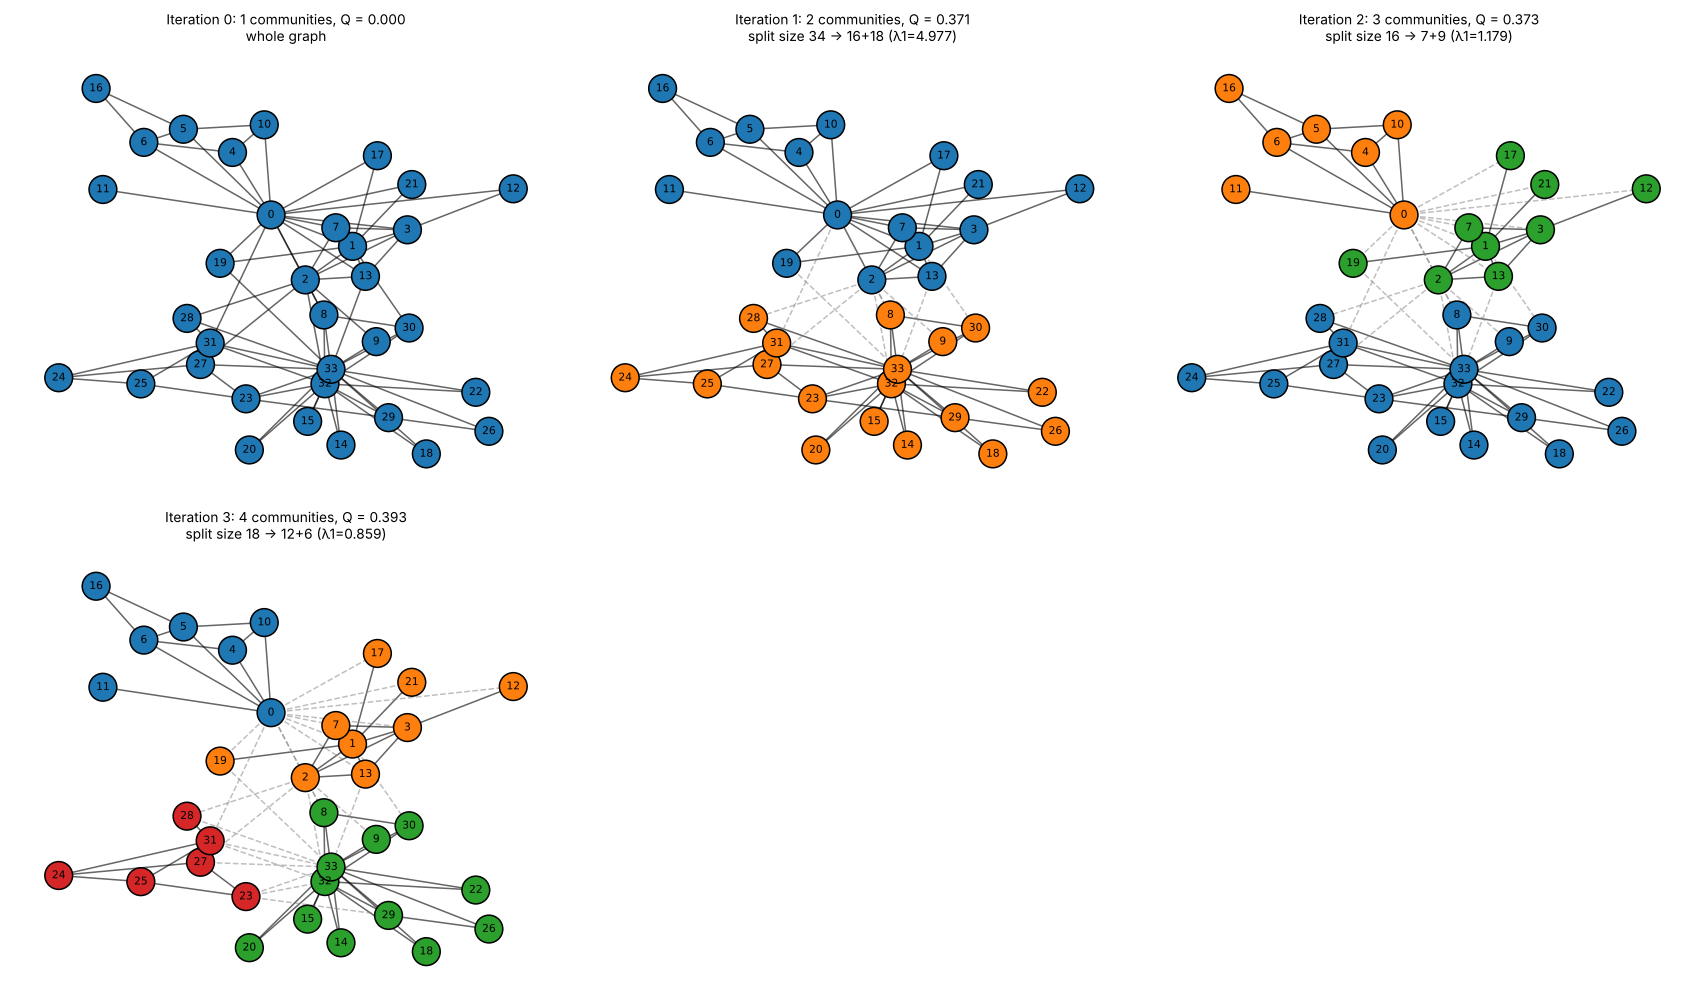

In [8]:
pos = nx.spring_layout(G, k=0.9, iterations=200, seed=7)   # fixed layout reused for every figure
palette = plt.get_cmap('tab10').colors

def draw_partition(ax, partition, title):
    lab = {v: ci for ci, c in enumerate(partition) for v in c}
    colors = [palette[lab[v] % 10] for v in nodes]
    inter = [(u, v) for u, v in G.edges() if lab[u] != lab[v]]
    intra = [(u, v) for u, v in G.edges() if lab[u] == lab[v]]
    nx.draw_networkx_edges(G, pos, edgelist=intra, ax=ax, alpha=0.6)
    nx.draw_networkx_edges(G, pos, edgelist=inter, ax=ax, alpha=0.5, style='dashed', edge_color='gray')
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=330, ax=ax, edgecolors='k')
    nx.draw_networkx_labels(G, pos, font_size=7, ax=ax)
    ax.set_title(title, fontsize=9); ax.axis('off')

cols = 3
rows = int(np.ceil(len(history) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 4.6 * rows))
axes = np.atleast_1d(axes).ravel()
for ax, h in zip(axes, history):
    draw_partition(ax, h['partition'], f"Iteration {h['it']}: {len(h['partition'])} communities, Q = {h['Q']:.3f}\n{h['note']}")
for ax in axes[len(history):]: ax.axis('off')
plt.tight_layout(); plt.savefig('partitions.png', bbox_inches='tight'); plt.show()

## 6. Metric evolution across iterations

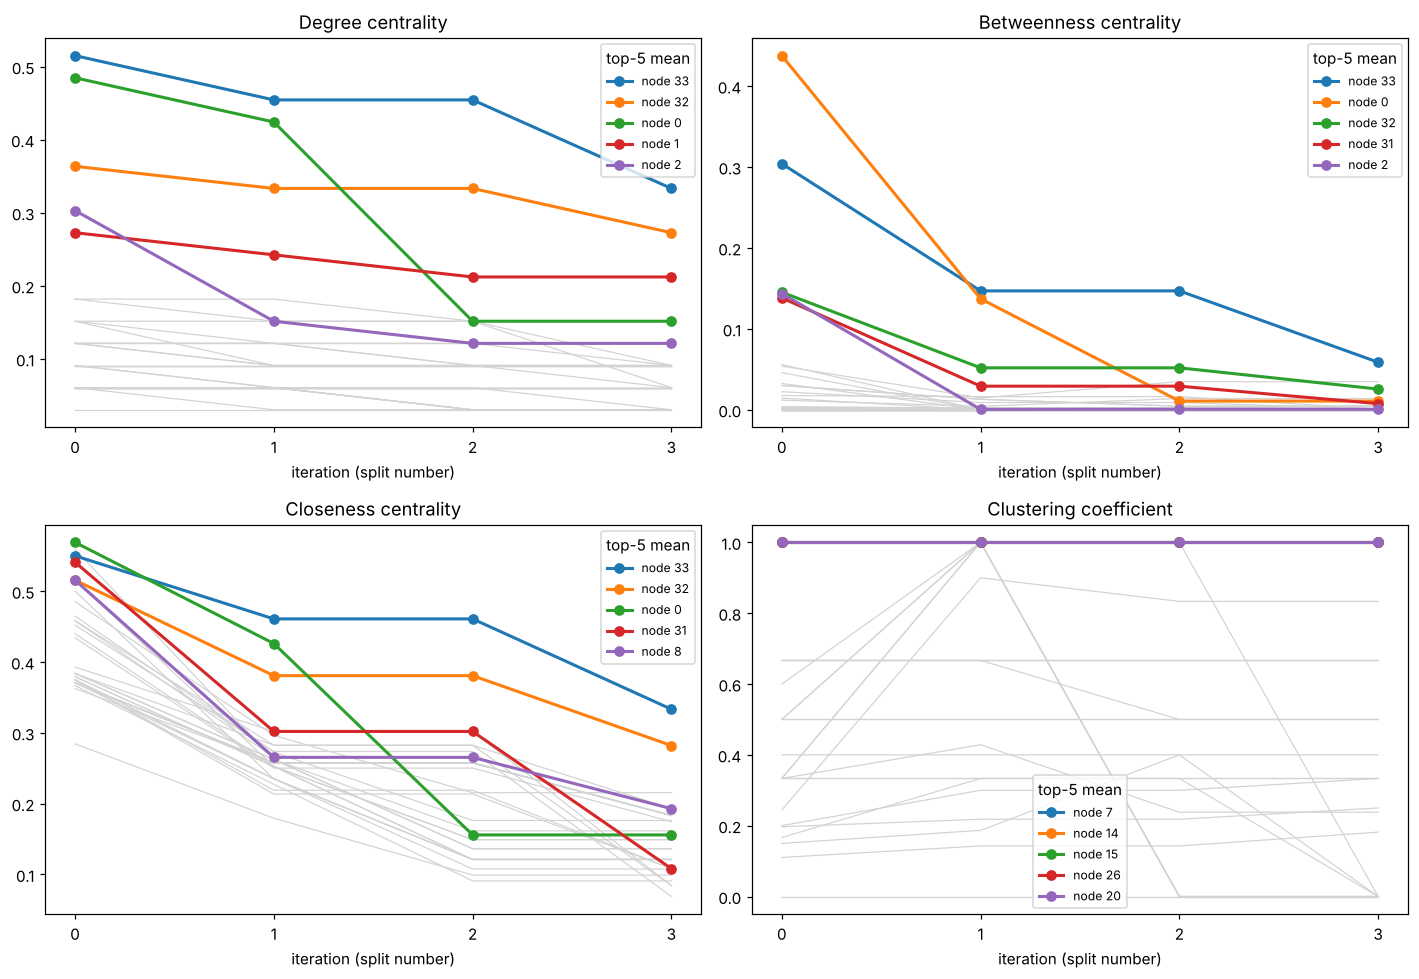

In [9]:
iters = sorted(metrics)
names = list(metrics[0].keys())
M = {name: np.array([[metrics[t][name][v] for t in iters] for v in nodes]) for name in names}  # (n, T)

# average value over iterations -> highlight the top 5 nodes per metric
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, name in zip(axes.ravel(), names):
    top = np.argsort(-M[name].mean(axis=1))[:5]
    for v in nodes:
        if v in top: continue
        ax.plot(iters, M[name][v], color='lightgray', lw=0.8, zorder=1)
    for v in top:
        ax.plot(iters, M[name][v], marker='o', lw=2, label=f"node {v}", zorder=3)
    ax.set_title(name); ax.set_xlabel('iteration (split number)'); ax.set_xticks(iters)
    ax.legend(fontsize=8, title='top-5 mean', ncol=1)
plt.tight_layout(); plt.savefig('metric_evolution_lines.png', bbox_inches='tight'); plt.show()

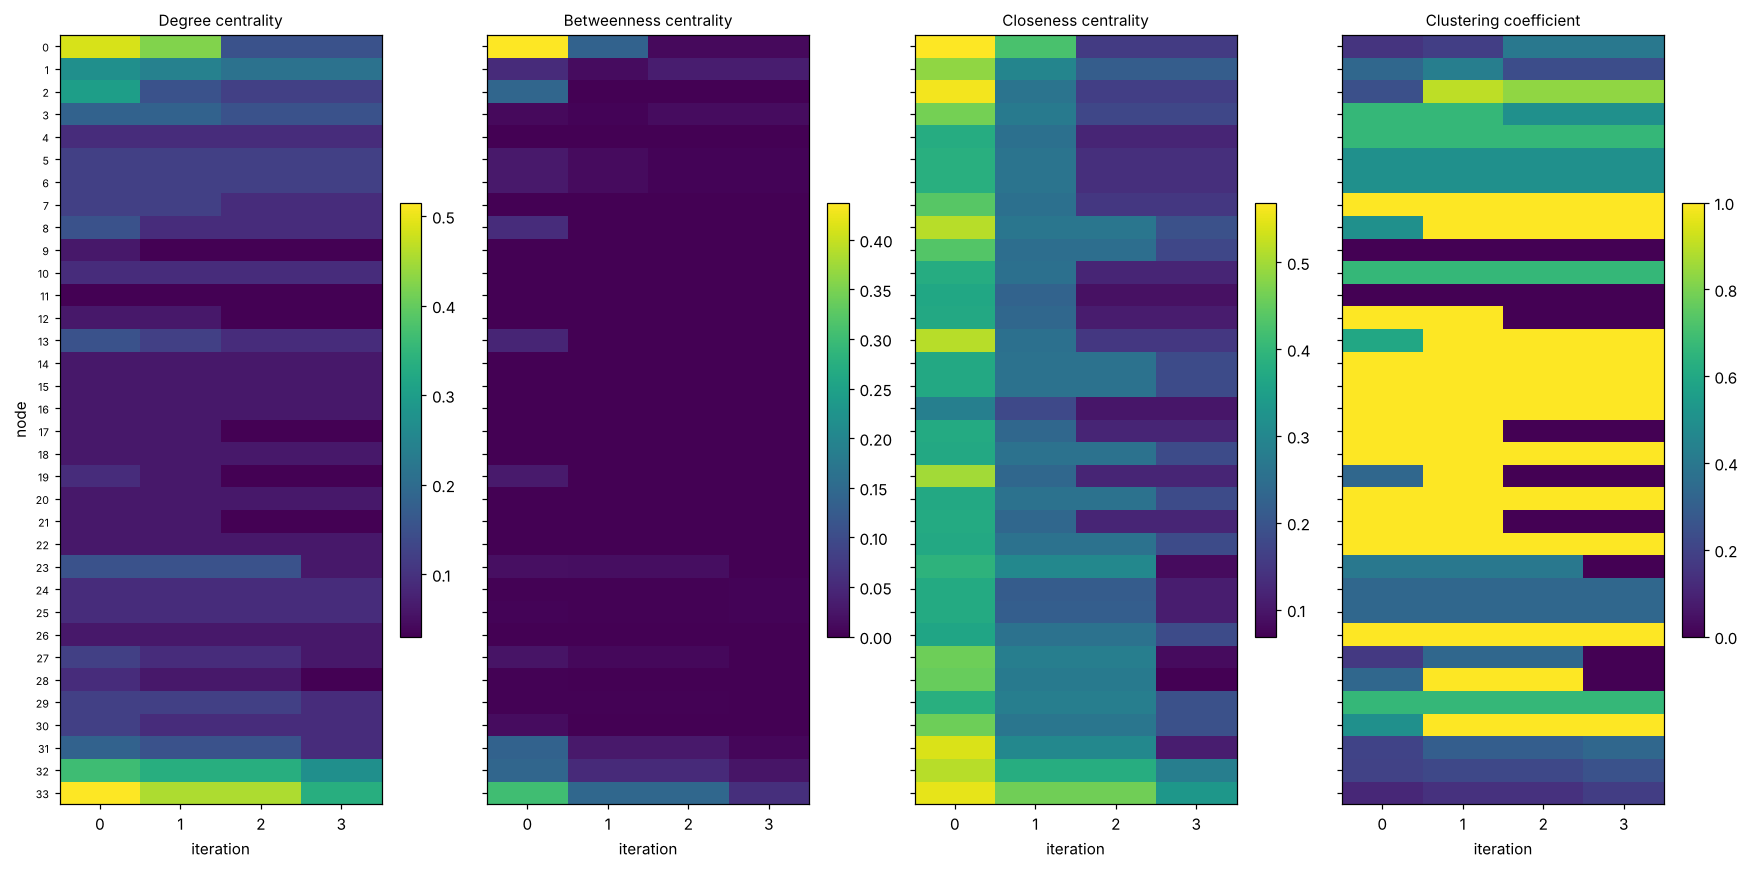

In [10]:
# Every node, every metric: heatmaps (rows = nodes, columns = iterations)
fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharey=True)
for ax, name in zip(axes, names):
    im = ax.imshow(M[name], aspect='auto', cmap='viridis')
    ax.set_title(name, fontsize=10); ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_xlabel('iteration'); ax.set_yticks(range(n)); ax.set_yticklabels(nodes, fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.06)
axes[0].set_ylabel('node')
plt.tight_layout(); plt.savefig('metric_evolution_heatmaps.png', bbox_inches='tight'); plt.show()

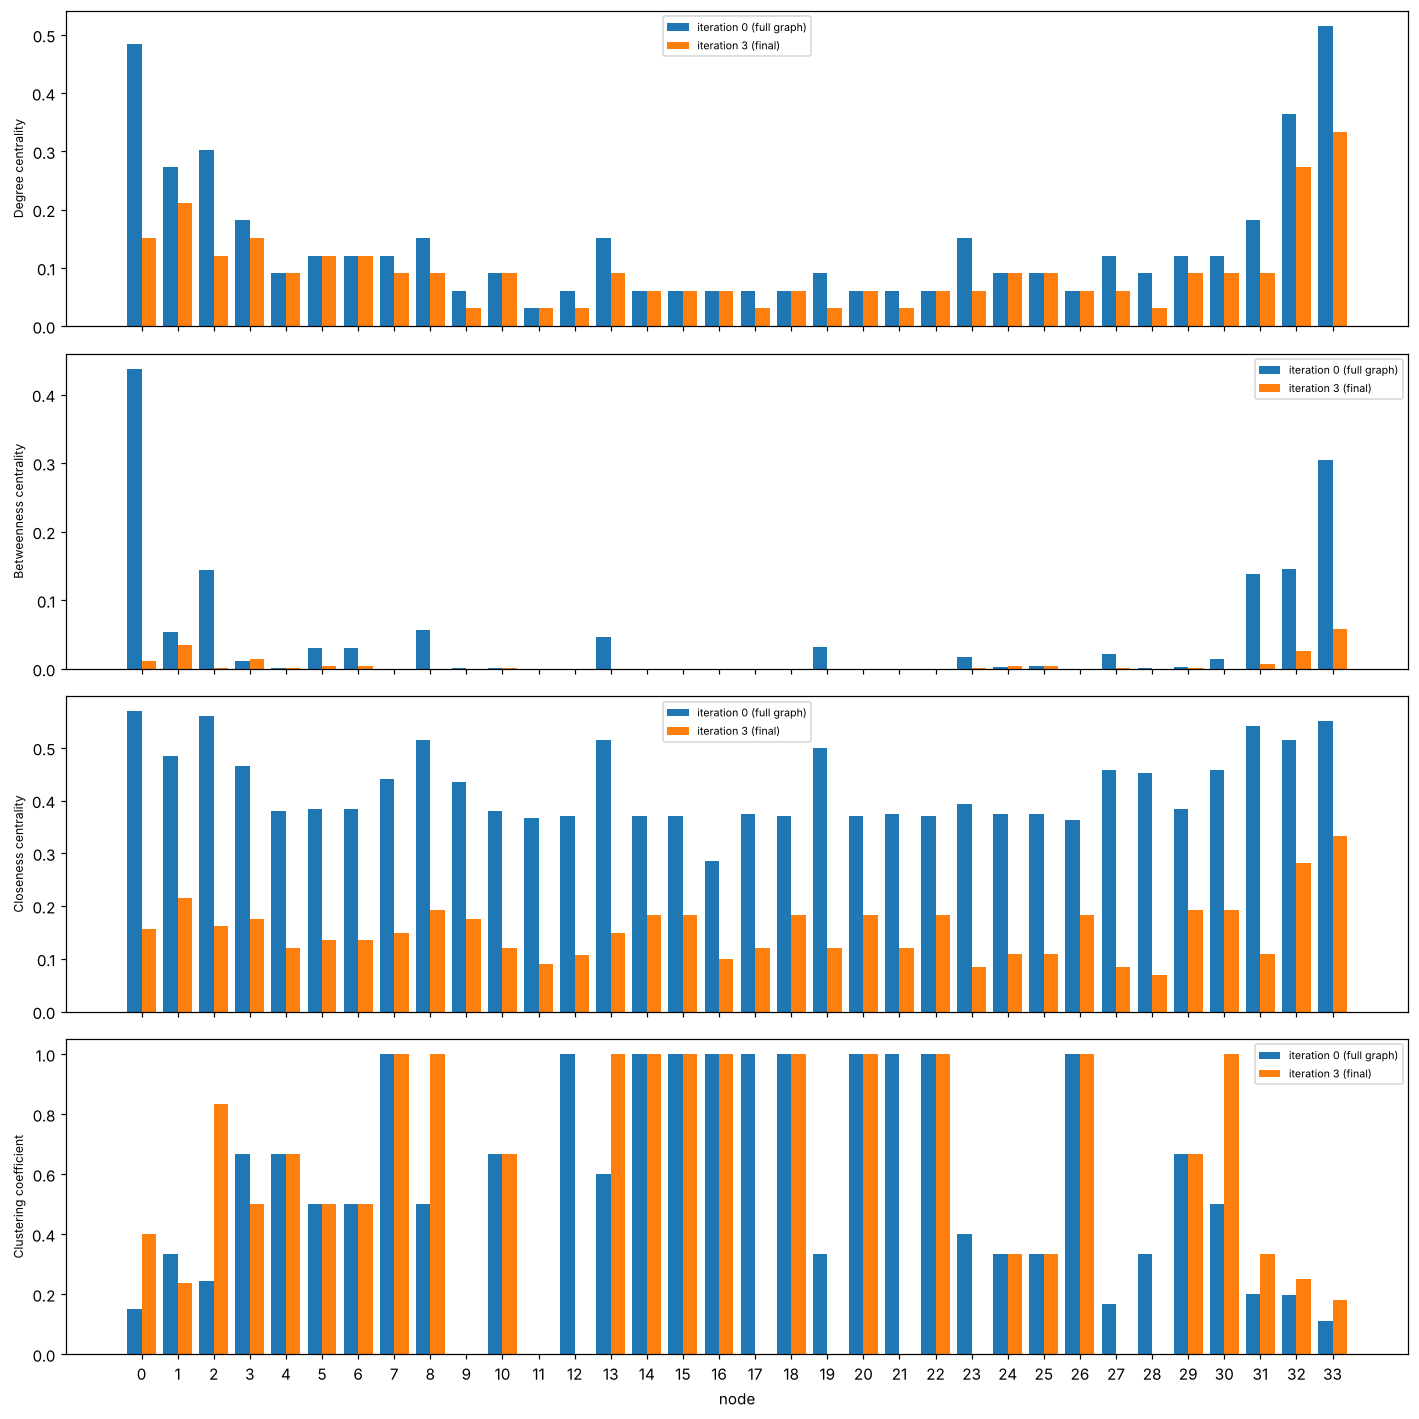

In [11]:
# Per-node bar plots for each metric (initial graph vs final partition)
fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True)
w = 0.4
for ax, name in zip(axes, names):
    ax.bar(np.array(nodes) - w/2, M[name][:, 0],  w, label='iteration 0 (full graph)')
    ax.bar(np.array(nodes) + w/2, M[name][:, -1], w, label=f'iteration {iters[-1]} (final)')
    ax.set_ylabel(name, fontsize=8); ax.legend(fontsize=7)
axes[-1].set_xticks(nodes); axes[-1].set_xlabel('node')
plt.tight_layout(); plt.savefig('metric_evolution_bars.png', bbox_inches='tight'); plt.show()

### Ranking tables

In [12]:
def top(name, t, r=5):
    vals = M[name][:, t]
    idx = np.argsort(-vals)[:r]
    return [(int(v), round(float(vals[v]), 3)) for v in idx]

for name in names:
    print(f"\n{name}")
    print("  iteration 0  :", top(name, 0))
    print(f"  iteration {iters[-1]}  :", top(name, -1))

# how often is each node in the top-5 across iterations (all four centrality-type metrics)?
from collections import Counter
cnt = Counter()
for name in names[:3]:
    for t in range(len(iters)):
        cnt.update(int(v) for v in np.argsort(-M[name][:, t])[:5])
print("\nTop-5 appearances (degree/betweenness/closeness x all iterations):", cnt.most_common(8))


Degree centrality
  iteration 0  : [(33, 0.515), (0, 0.485), (32, 0.364), (2, 0.303), (1, 0.273)]
  iteration 3  : [(33, 0.333), (32, 0.273), (1, 0.212), (0, 0.152), (3, 0.152)]

Betweenness centrality
  iteration 0  : [(0, 0.438), (33, 0.304), (32, 0.145), (2, 0.144), (31, 0.138)]
  iteration 3  : [(33, 0.059), (1, 0.035), (32, 0.026), (3, 0.014), (0, 0.011)]

Closeness centrality
  iteration 0  : [(0, 0.569), (2, 0.559), (33, 0.55), (31, 0.541), (8, 0.516)]
  iteration 3  : [(33, 0.333), (32, 0.282), (1, 0.215), (8, 0.193), (30, 0.193)]

Clustering coefficient
  iteration 0  : [(7, 1.0), (12, 1.0), (15, 1.0), (14, 1.0), (20, 1.0)]
  iteration 3  : [(7, 1.0), (14, 1.0), (15, 1.0), (8, 1.0), (13, 1.0)]

Top-5 appearances (degree/betweenness/closeness x all iterations): [(33, 12), (32, 11), (0, 9), (1, 7), (31, 7), (23, 4), (2, 3), (3, 3)]


## 7. Discussion

**Result.** The first split (λ₁ = 4.977) separates the club into 16 + 18 members and agrees with the real Mr. Hi / Officer split for 33 of 34 members; the only error is node 8, who has ties to both sides. Interestingly, this spectral split has *higher* modularity (Q = 0.3715) than the true split (Q = 0.3582). Recursion then stops at **4 communities, Q = 0.3934**, which matches the value reported by Newman (2006) for this network. The 7-, 12- and 6-node groups have λ₁ ≈ 0, and the 9-node group has λ₁ = 0.06 > 0 but the rounded split would *lower* Q, so it is rejected.

**Which nodes stay central.** Nodes **33** and **32** (the officer's side) and node **0** (Mr. Hi) are the top-ranked nodes across the iterations: node 33 is the top node by degree and the top node in the top-5 tally, and nodes 0, 32, 33 lead betweenness at the start. These are the two faction leaders (0 and 33) and the main lieutenant (32). Node 1 rises to second place in betweenness in the final partition, because it is the hub of its 9-node community; node 31 is among the top-5 brokers in the original graph.

**How community structure changes the metrics.**
* *Degree centrality* only drops, since cutting inter-community edges can only remove edges; it drops most for nodes with many cross-faction ties (e.g. node 0 falls from 0.485 to 0.152 because most of its neighbours end up in other communities).
* *Betweenness* collapses for everyone (e.g. node 0: 0.438 → 0.011) because shortest paths that used to cross between factions no longer exist. Node 0 was the biggest *broker* in the full graph and loses most of that role; node 33, whose community is large and internally well connected, keeps the highest betweenness. This shows that betweenness in the full graph is driven by bridging between communities.
* *Closeness* (NetworkX's version, which is scaled for disconnected graphs) falls for nodes whose community is small, because they can only reach few nodes; it falls for every node (all 34), and stays highest inside the largest community (12 nodes, containing 32 and 33; mean closeness 0.206 vs 0.094 in the 6-node community).
* *Clustering* can move in either direction: nodes already inside tight groups (e.g. 7, 14, 15 at 1.0) are unchanged, 9 nodes lose clustering (their triangles used a cut edge), and 8 nodes gain it, because cutting cross-community edges removes neighbours that were not connected to each other (node 0: 0.15 → 0.40, node 2: 0.24 → 0.83, node 8: 0.5 → 1.0). Triangles live mostly inside communities, whereas the cut edges are what gave hubs their global reach.

**Handout matrix vs. generalised matrix.** Using the plain block `B[C][:,C]` (as written in the handout) gives 5 communities and a higher Q (0.4094) than the generalised matrix (0.3934). That does not contradict the theory: recursive bisection is a greedy heuristic and ends at a local optimum, and the plain block just happens to take a different path here. But the plain block does not satisfy `ΔQ = sᵀB⁽ᶜ⁾s / 4m`, so the stopping rule `λ₁ ≤ 0` has no guarantee behind it; the generalised matrix does.

**Caveat on the metrics.** The metrics are computed on the graph that keeps only intra-community edges after each split (iteration 0 = the original graph); computed on the original graph they would not change from one iteration to the next.

**Reference.** M. E. J. Newman, *Modularity and community structure in networks*, PNAS 103(23):8577–8582 (2006).